# Part D: Car Dependency and Socioeconomic Equity

This notebook examines the spatial relationship between car dependency and socioeconomic disadvantage across Burnie. The primary 30-minute Car Dependency Index is joined to SA1 population and SEIFA IRSD data to identify areas where limited public-transport accessibility may overlap with greater socioeconomic disadvantage.

In [2]:
# Import libraries

from pathlib import Path

import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt

print("Car dependency and equity environment is working.")

Car dependency and equity environment is working.


In [3]:
# Set project paths

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

analysis_ready = (
    project_root / "data" / "processed" / "analysis_ready"
)

print("Analysis-ready folder exists:", analysis_ready.exists())

Analysis-ready folder exists: True


## D1. Combine Car Dependency and Socioeconomic Data

The primary 30-minute CDI results are joined to the prepared SA1 population and SEIFA IRSD dataset using the 2021 SA1 code.

In [4]:
# Load the Burnie SA1 socioeconomic layer

burnie_equity = gpd.read_file(
    analysis_ready / "burnie_sa1_seifa.gpkg"
)

burnie_equity["SA1_CODE_2021"] = (
    burnie_equity["SA1_CODE_2021"].astype(str)
)

# Load the 30-minute CDI results

cdi_30 = pd.read_csv(
    analysis_ready / "cdi_30min.csv",
    dtype={"from_id": str}
)

print("Burnie SA1 records:", len(burnie_equity))
print("CDI records:", len(cdi_30))

display(cdi_30.head())

Burnie SA1 records: 56
CDI records: 56


,from_id,threshold_min,car_access,pt_access,access_gap,CDI
0,60401107501,30,1.0,0.607143,0.392857,0.244444
1,60401107502,30,1.0,0.678571,0.321429,0.191489
2,60401107503,30,1.0,0.494643,0.505357,0.338112
3,60401107504,30,1.0,0.582143,0.417857,0.264108
4,60401107505,30,1.0,0.382143,0.617857,0.447028


In [5]:
# Join CDI to the Burnie SA1 socioeconomic data

burnie_equity = burnie_equity.merge(
    cdi_30[
        [
            "from_id",
            "car_access",
            "pt_access",
            "access_gap",
            "CDI"
        ]
    ],
    left_on="SA1_CODE_2021",
    right_on="from_id",
    how="left"
)

print("SA1s after join:", len(burnie_equity))
print("SA1s with CDI:", burnie_equity["CDI"].notna().sum())
print("SA1s without CDI:", burnie_equity["CDI"].isna().sum())

print("SA1s with IRSD:", burnie_equity["IRSD_Score"].notna().sum())
print("SA1s without IRSD:", burnie_equity["IRSD_Score"].isna().sum())

SA1s after join: 56
SA1s with CDI: 55
SA1s without CDI: 1
SA1s with IRSD: 54
SA1s without IRSD: 2


## D2. Relationship Between Car Dependency and Socioeconomic Disadvantage

The relationship between the 30-minute Car Dependency Index and SEIFA IRSD is examined across Burnie SA1s. Higher CDI values indicate greater car advantage, while lower IRSD scores indicate greater socioeconomic disadvantage. Therefore, a negative relationship would indicate that more disadvantaged areas tend to experience greater car dependency.

In [6]:
# Keep SA1s with both CDI and IRSD values

equity_valid = burnie_equity[
    burnie_equity["CDI"].notna()
    & burnie_equity["IRSD_Score"].notna()
].copy()

print("SA1s available for CDI–IRSD analysis:", len(equity_valid))

print("\nCDI summary:")
print(equity_valid["CDI"].describe())

print("\nIRSD summary:")
print(equity_valid["IRSD_Score"].describe())

SA1s available for CDI–IRSD analysis: 53

CDI summary:
count    53.000000
mean      0.625825
std       0.266908
min       0.149897
25%       0.432225
50%       0.635036
75%       0.904762
max       1.000000
Name: CDI, dtype: float64

IRSD summary:
count      53.000000
mean      915.762689
std       112.106913
min       555.659331
25%       868.587986
50%       915.043194
75%      1002.529157
max      1120.573408
Name: IRSD_Score, dtype: float64


In [7]:
# Calculate Spearman correlation between CDI and IRSD

spearman_r = equity_valid["CDI"].corr(
    equity_valid["IRSD_Score"],
    method="spearman"
)

print("Spearman correlation between CDI and IRSD:")
print(round(spearman_r, 3))

Spearman correlation between CDI and IRSD:
0.492


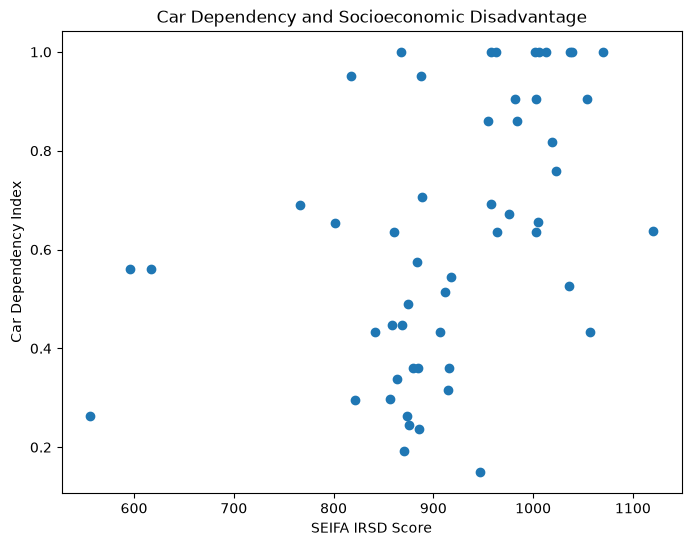

In [8]:
# Plot CDI against IRSD

fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    equity_valid["IRSD_Score"],
    equity_valid["CDI"]
)

ax.set_xlabel("SEIFA IRSD Score")
ax.set_ylabel("Car Dependency Index")
ax.set_title("Car Dependency and Socioeconomic Disadvantage")

plt.show()

In [9]:
# Test the statistical significance of the CDI–IRSD relationship

from scipy.stats import spearmanr

spearman_r, spearman_p = spearmanr(
    equity_valid["CDI"],
    equity_valid["IRSD_Score"]
)

print("Spearman r:", round(spearman_r, 3))
print("p-value:", round(spearman_p, 4))

Spearman r: 0.492
p-value: 0.0002


In [10]:
# Identify SA1s with both high car dependency and greater disadvantage

high_cdi_threshold = equity_valid["CDI"].quantile(0.75)
disadvantage_threshold = equity_valid["IRSD_Score"].quantile(0.25)

print("High CDI threshold:", round(high_cdi_threshold, 3))
print("Greater disadvantage threshold:", round(disadvantage_threshold, 1))

equity_valid["equity_priority"] = (
    (equity_valid["CDI"] >= high_cdi_threshold)
    & (equity_valid["IRSD_Score"] <= disadvantage_threshold)
)

print(
    "High-dependency + greater-disadvantage SA1s:",
    equity_valid["equity_priority"].sum()
)

display(
    equity_valid.loc[
        equity_valid["equity_priority"],
        [
            "SA1_CODE_2021",
            "Population",
            "IRSD_Score",
            "IRSD_Aus_Decile",
            "car_access",
            "pt_access",
            "CDI"
        ]
    ].sort_values("CDI", ascending=False)
)

High CDI threshold: 0.905
Greater disadvantage threshold: 868.6
High-dependency + greater-disadvantage SA1s: 2


,SA1_CODE_2021,Population,IRSD_Score,IRSD_Aus_Decile,car_access,pt_access,CDI
22,60401107709,411.0,867.441955,1.0,1.0,0.000,1.00000
53,60401108009,253.0,817.790136,1.0,1.0,0.025,0.95122


## D3. Equity Priority Areas

Although car dependency is not generally highest in the most disadvantaged SA1s, two areas combine very high car dependency with relatively greater socioeconomic disadvantage. These areas are identified using the upper quartile of CDI and lower quartile of IRSD within Burnie and are highlighted as potential transport-equity priority areas.

In [11]:
# Add the equity-priority classification back to the full spatial layer

priority_codes = set(
    equity_valid.loc[
        equity_valid["equity_priority"],
        "SA1_CODE_2021"
    ]
)

burnie_equity["equity_priority"] = (
    burnie_equity["SA1_CODE_2021"].isin(priority_codes)
)

print(
    "Equity-priority SA1s:",
    burnie_equity["equity_priority"].sum()
)

Equity-priority SA1s: 2


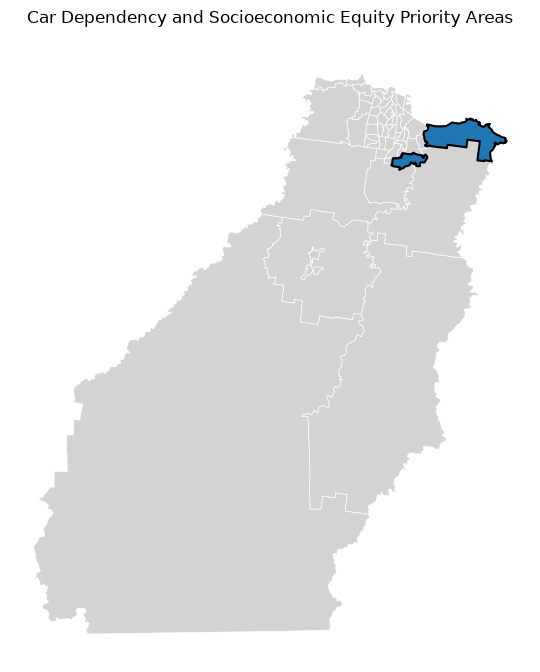

In [12]:
# Map high car-dependency and greater-disadvantage SA1s

fig, ax = plt.subplots(figsize=(8, 8))

# All Burnie SA1s
burnie_equity.plot(
    ax=ax,
    facecolor="lightgrey",
    edgecolor="white",
    linewidth=0.5
)

# Highlight equity-priority SA1s
burnie_equity[
    burnie_equity["equity_priority"]
].plot(
    ax=ax,
    edgecolor="black",
    linewidth=1.5
)

ax.set_title(
    "Car Dependency and Socioeconomic Equity Priority Areas"
)

ax.set_axis_off()

plt.show()

In [13]:
# Save the car-dependency and equity dataset

burnie_equity.to_file(
    analysis_ready / "burnie_car_dependency_equity.gpkg",
    driver="GPKG"
)

print("Equity dataset saved.")

Equity dataset saved.


## D4. Final Six-Category Car Dependency and Equity Analysis

The socioeconomic equity analysis is repeated using the final six-category Car Dependency Index. This expanded accessibility framework includes four essential-service categories and two local-opportunity categories: greenspace and leisure. The 30-minute threshold remains the primary scenario.

In [15]:
# Load the final six-category 30-minute CDI

cdi_30_final = pd.read_csv(
    analysis_ready / "cdi_30min_6categories.csv",
    dtype={"from_id": str}
)

print("Final CDI records:", len(cdi_30_final))
print("Defined CDI values:", cdi_30_final["CDI"].notna().sum())

print("\nFinal CDI summary:")
print(cdi_30_final["CDI"].describe())

display(cdi_30_final.head())

Final CDI records: 56
Defined CDI values: 56

Final CDI summary:
count    56.000000
mean      0.667200
std       0.234142
min       0.226966
25%       0.472518
50%       0.665904
75%       0.909983
max       1.000000
Name: CDI, dtype: float64


,from_id,threshold_min,car_access,pt_access,access_gap,CDI
0,60401107501,30,1.0,0.468437,0.531563,0.361992
1,60401107502,30,1.0,0.538492,0.461508,0.299974
2,60401107503,30,1.0,0.403907,0.596093,0.424596
3,60401107504,30,1.0,0.490018,0.509982,0.342265
4,60401107505,30,1.0,0.309676,0.690324,0.527095


In [16]:
# Load a fresh copy of the Burnie SA1 socioeconomic layer

burnie_equity_6 = gpd.read_file(
    analysis_ready / "burnie_sa1_seifa.gpkg"
)

burnie_equity_6["SA1_CODE_2021"] = (
    burnie_equity_6["SA1_CODE_2021"].astype(str)
)

# Join the final six-category CDI

burnie_equity_6 = burnie_equity_6.merge(
    cdi_30_final[
        [
            "from_id",
            "car_access",
            "pt_access",
            "access_gap",
            "CDI"
        ]
    ],
    left_on="SA1_CODE_2021",
    right_on="from_id",
    how="left"
)

print("Burnie SA1s:", len(burnie_equity_6))
print("SA1s with final CDI:",
      burnie_equity_6["CDI"].notna().sum())

print("SA1s with IRSD:",
      burnie_equity_6["IRSD_Score"].notna().sum())

print("SA1s with both CDI and IRSD:",
      (
          burnie_equity_6["CDI"].notna()
          & burnie_equity_6["IRSD_Score"].notna()
      ).sum()
)

Burnie SA1s: 56
SA1s with final CDI: 56
SA1s with IRSD: 54
SA1s with both CDI and IRSD: 54


### D5. Final CDI–IRSD Relationship

The relationship between the final six-category 30-minute Car Dependency Index and socioeconomic disadvantage is examined using Spearman rank correlation. Higher CDI indicates greater car advantage, while lower IRSD scores indicate greater socioeconomic disadvantage.

In [17]:
# Keep SA1s with both final CDI and IRSD data

equity_valid_6 = burnie_equity_6[
    burnie_equity_6["CDI"].notna()
    & burnie_equity_6["IRSD_Score"].notna()
].copy()

print(
    "SA1s available for final CDI–IRSD analysis:",
    len(equity_valid_6)
)

SA1s available for final CDI–IRSD analysis: 54


In [18]:
# Calculate Spearman correlation for the final six-category CDI

from scipy.stats import spearmanr

spearman_r_6, spearman_p_6 = spearmanr(
    equity_valid_6["CDI"],
    equity_valid_6["IRSD_Score"]
)

print("Spearman r:", round(spearman_r_6, 3))
print("p-value:", round(spearman_p_6, 4))

Spearman r: 0.531
p-value: 0.0


In [19]:
# Identify final equity-priority SA1s

high_cdi_threshold_6 = (
    equity_valid_6["CDI"].quantile(0.75)
)

disadvantage_threshold_6 = (
    equity_valid_6["IRSD_Score"].quantile(0.25)
)

equity_valid_6["equity_priority"] = (
    (equity_valid_6["CDI"] >= high_cdi_threshold_6)
    & (
        equity_valid_6["IRSD_Score"]
        <= disadvantage_threshold_6
    )
)

print(
    "High CDI threshold:",
    round(high_cdi_threshold_6, 3)
)

print(
    "Greater disadvantage threshold:",
    round(disadvantage_threshold_6, 1)
)

print(
    "Final equity-priority SA1s:",
    equity_valid_6["equity_priority"].sum()
)

display(
    equity_valid_6.loc[
        equity_valid_6["equity_priority"],
        [
            "SA1_CODE_2021",
            "Population",
            "IRSD_Score",
            "IRSD_Aus_Decile",
            "car_access",
            "pt_access",
            "CDI"
        ]
    ].sort_values(
        "CDI",
        ascending=False
    )
)

High CDI threshold: 0.91
Greater disadvantage threshold: 869.1
Final equity-priority SA1s: 2


,SA1_CODE_2021,Population,IRSD_Score,IRSD_Aus_Decile,car_access,pt_access,CDI
22,60401107709,411.0,867.441955,1.0,1.0,0.000000,1.000000
53,60401108009,253.0,817.790136,1.0,1.0,0.037393,0.927909


In [20]:
# Display the p-value more accurately

print("Spearman r:", round(spearman_r_6, 3))
print(f"p-value: {spearman_p_6:.6f}")
print(f"p-value scientific notation: {spearman_p_6:.3e}")

Spearman r: 0.531
p-value: 0.000036
p-value scientific notation: 3.567e-05


In [21]:
# Add the final priority classification to the spatial dataset

priority_codes_6 = set(
    equity_valid_6.loc[
        equity_valid_6["equity_priority"],
        "SA1_CODE_2021"
    ]
)

burnie_equity_6["equity_priority"] = (
    burnie_equity_6["SA1_CODE_2021"].isin(priority_codes_6)
)

burnie_equity_6.to_file(
    analysis_ready / "burnie_car_dependency_equity_6categories.gpkg",
    driver="GPKG"
)

print("Final six-category equity dataset saved.")

Final six-category equity dataset saved.
